In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [6]:
df = pd.read_csv("Amazon Sale Report.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


/tmp/ipykernel_2704/3226373106.py:1: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Amazon Sale Report.csv")


In [9]:
print("Number of rows and columns:", df.shape)
print("First 5 rows\n",df.head())
print(df.info())
print(df.describe())

Number of rows and columns: (128975, 24)
First 5 rows
    index             Order ID      Date                        Status  \
0      0  405-8078784-5731545  04-30-22                     Cancelled   
1      1  171-9198151-1101146  04-30-22  Shipped - Delivered to Buyer   
2      2  404-0687676-7273146  04-30-22                       Shipped   
3      3  403-9615377-8133951  04-30-22                     Cancelled   
4      4  407-1069790-7240320  04-30-22                       Shipped   

  Fulfilment Sales Channel  ship-service-level    Style              SKU  \
0   Merchant      Amazon.in           Standard   SET389   SET389-KR-NP-S   
1   Merchant      Amazon.in           Standard  JNE3781  JNE3781-KR-XXXL   
2     Amazon      Amazon.in          Expedited  JNE3371    JNE3371-KR-XL   
3   Merchant      Amazon.in           Standard    J0341       J0341-DR-L   
4     Amazon      Amazon.in          Expedited  JNE3671  JNE3671-TU-XXXL   

        Category  ... currency  Amount    ship-ci

In [10]:
#Data Cleaning
df.columns = df.columns.str.strip()
df = df.drop(columns=["index", "Unnamed: 22"], errors="ignore")
print(df.columns.tolist())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.dropna(subset=["Date", "Amount", "Qty"])
df = df[df["Qty"] > 0]
df = df[df["Amount"] > 0]
df = df[~df["Status"].str.contains("cancel", case=False, na=False)]
print("Rows after cleaning:", df.shape[0])
print("Missing dates:", df["Date"].isnull().sum())
print("Missing amounts:", df["Amount"].isnull().sum())
print("Missing quantities:", df["Qty"].isnull().sum())

['Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids', 'B2B', 'fulfilled-by']
Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6872
Qty                       0
currency               7795
Amount                 7795
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49153
B2B                       0
fulfilled-by          89698
dtype: int64
Duplicate rows: 6
Rows after cleaning: 108071
Missing dates: 0
Missing amounts: 0
Missing qua

In [12]:
# Convert Date into date format
df["Date"] = pd.to_datetime(df["Date"], format="%m-%d-%y", errors="coerce")
# Convert Amount and Qty into numeric values
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")
df["Qty"] = pd.to_numeric(df["Qty"], errors="coerce")



In [13]:
# Display the different order statuses
print(df["Status"].value_counts())

Status
Shipped                          76078
Shipped - Delivered to Buyer     28045
Shipped - Returned to Seller      1899
Shipped - Picked Up                945
Pending                            639
Pending - Waiting for Pick Up      272
Shipped - Returning to Seller      143
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipped - Lost in Transit            3
Shipped - Damaged                    1
Name: count, dtype: int64


In [14]:
# Extract year, month, and day
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
# Create a month column for monthly analysis
df["Year-Month"] = df["Date"].dt.strftime("%Y-%m")
# Use Amount as the recorded sales amount
df["Revenue"] = df["Amount"]
# Display the new columns
display(df[["Date","Year","Month","Day","Year-Month","Amount","Revenue"]].head())

,Date,Year,Month,Day,Year-Month,Amount,Revenue
1,2022-04-30,2022,4,30,2022-04,406.0,406.0
2,2022-04-30,2022,4,30,2022-04,329.0,329.0
4,2022-04-30,2022,4,30,2022-04,574.0,574.0
5,2022-04-30,2022,4,30,2022-04,824.0,824.0
6,2022-04-30,2022,4,30,2022-04,653.0,653.0


In [19]:
# Calculate total revenue for each month
monthly_sales = df.groupby("Year-Month")["Revenue"].sum()
# Display monthly sales
print(monthly_sales)
# Calculate percentage change in monthly revenue
monthly_change = monthly_sales.pct_change() * 100
print("Monthly Revenue Change (%):")
print(monthly_change.round(2))

Year-Month
2022-03       94810.0
2022-04    26234520.0
2022-05    23953534.0
2022-06    21390530.0
Name: Revenue, dtype: float64
Monthly Revenue Change (%):
Year-Month
2022-03         NaN
2022-04    27570.63
2022-05       -8.69
2022-06      -10.70
Name: Revenue, dtype: float64


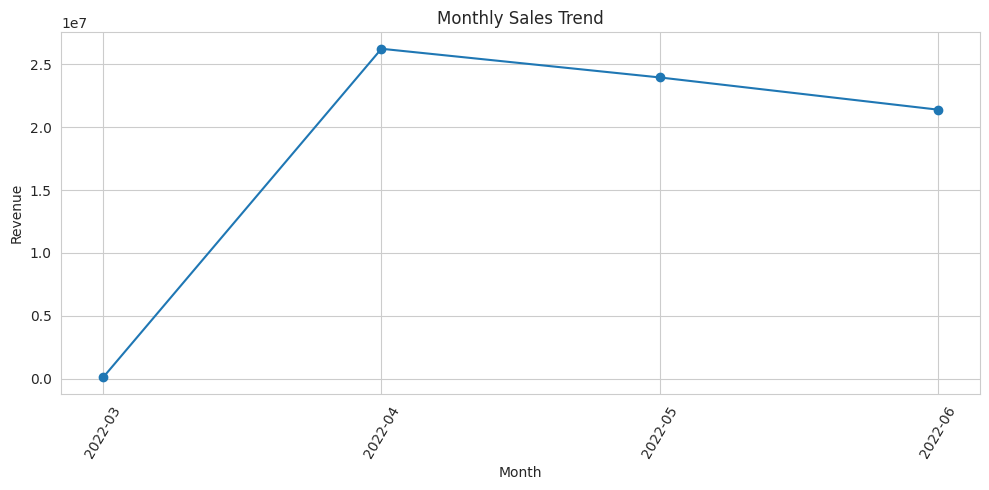

In [21]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Category
Set              35731673.0
kurta            19425870.0
Western Dress    10209590.0
Top               4904066.0
Ethnic Dress       732744.0
Blouse             418389.0
Bottom             135453.0
Saree              114694.0
Dupatta               915.0
Name: Revenue, dtype: float64


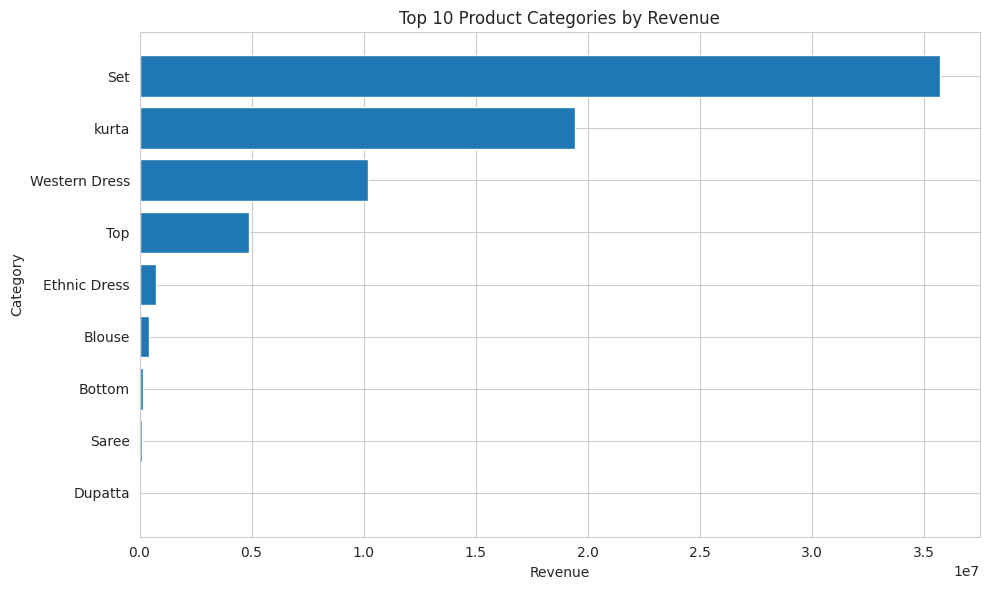

In [22]:
# Calculate total revenue for each category
category_sales = df.groupby("Category")["Revenue"].sum()
# Sort categories from highest to lowest revenue
category_sales = category_sales.sort_values(ascending=False)
print(category_sales)
# Select the top 10 categories
top_categories = category_sales.head(10)
# Create a bar chart
plt.figure(figsize=(10, 6))
plt.barh(top_categories.index, top_categories.values)
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [23]:
# Remove rows where shipping state is missing
state_data = df.dropna(subset=["ship-state"])
# Calculate revenue for each state
state_sales = state_data.groupby("ship-state")["Revenue"].sum()
# Sort from highest to lowest
state_sales = state_sales.sort_values(ascending=False)
# Display the top 10 states
print(state_sales.head(10))

ship-state
MAHARASHTRA       12224770.0
KARNATAKA          9649981.0
TELANGANA          6290128.0
UTTAR PRADESH      6186656.0
TAMIL NADU         5954349.0
DELHI              3906089.0
KERALA             3377321.0
WEST BENGAL        3207213.0
ANDHRA PRADESH     2882206.0
HARYANA            2654274.0
Name: Revenue, dtype: float64


In [24]:
# Compare monthly revenue for different categories
pivot_table = pd.pivot_table(
    df,
    values="Revenue",
    index="Year-Month",
    columns="Category",
    aggfunc="sum",
    fill_value=0
)

display(pivot_table)

Category,Blouse,Bottom,Dupatta,Ethnic Dress,Saree,Set,Top,Western Dress,kurta
Year-Month,,,,,,,,,
2022-03,280.0,0.0,0.0,0.0,0.0,51532.0,4511.0,5479.0,33008.0
2022-04,175677.0,59440.0,0.0,230631.0,49123.0,14124033.0,1672892.0,2683186.0,7239538.0
2022-05,144992.0,41986.0,0.0,269144.0,40190.0,11528223.0,1837175.0,3970177.0,6121647.0
2022-06,97440.0,34027.0,915.0,232969.0,25381.0,10027885.0,1389488.0,3550748.0,6031677.0


Fulfilment
Amazon      50593039.0
Merchant    21080355.0
Name: Revenue, dtype: float64


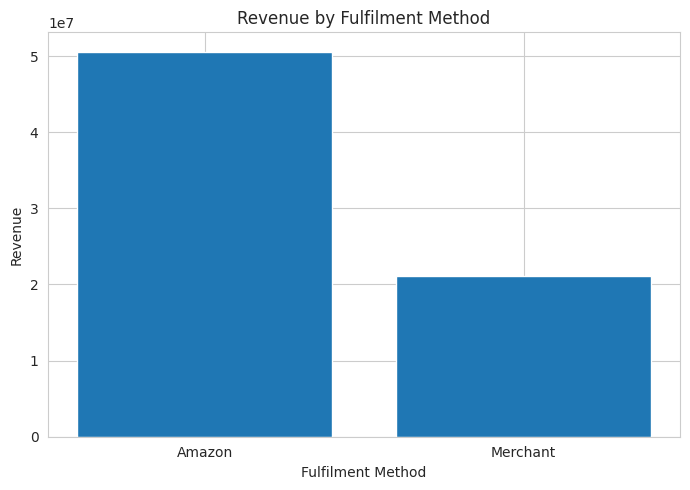

In [26]:
# Calculate revenue by fulfilment method
fulfilment_sales = df.groupby("Fulfilment")["Revenue"].sum()
# Sort from highest to lowest
fulfilment_sales = fulfilment_sales.sort_values(ascending=False)
print(fulfilment_sales)
plt.figure(figsize=(7, 5))
plt.bar(fulfilment_sales.index, fulfilment_sales.values)
plt.title("Revenue by Fulfilment Method")
plt.xlabel("Fulfilment Method")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()



In [29]:
# Calculate revenue for B2B and regular orders
b2b_sales = df.groupby("B2B")["Revenue"].sum()
print("Revenue by B2B status:")
print(b2b_sales)


Revenue by B2B status:
B2B
False    71113994.0
True       559400.0
Name: Revenue, dtype: float64


In [30]:
# Find the month with the highest revenue
best_month = monthly_sales.idxmax()
# Find the category with the highest revenue
best_category = category_sales.idxmax()
# Find the state with the highest revenue
best_state = state_sales.idxmax()
print("KEY FINDINGS")
print("Month with highest revenue:", best_month)
print("Highest revenue month total:", round(monthly_sales.max(), 2))
print("Top product category:", best_category)
print("Top state by revenue:", best_state)

KEY FINDINGS
Month with highest revenue: 2022-04
Highest revenue month total: 26234520.0
Top product category: Set
Top state by revenue: MAHARASHTRA


In [31]:
print("BUSINESS RECOMMENDATIONS")
print("1. Focus on product categories with high revenue.")
print("2. Study monthly sales changes to plan future promotions.")
print("3. Use state-wise sales results to plan regional marketing.")
print("4. Compare fulfilment methods to identify areas for improvement.")
print("5. Analyze customer purchase history in future to measure churn.")

BUSINESS RECOMMENDATIONS
1. Focus on product categories with high revenue.
2. Study monthly sales changes to plan future promotions.
3. Use state-wise sales results to plan regional marketing.
4. Compare fulfilment methods to identify areas for improvement.
5. Analyze customer purchase history in future to measure churn.
